> **A CHEM 438 final project from fall 2025**, shared as an example with the author's name removed. It used Our World in Data COVID table. The data files are not included, so the cells will not rerun here: read it top to bottom, the figures and results are saved in the notebook.


# Analysis of Hospital Facilities on COVID-19 spread and Death Rate

## Introduction

The COVID-19 pandemic lasted about 3 years in the United States, and the effects were felt around the world. While the global health emergency was declared over in May of 2023, COVID-19 is still around today and affects the health of many people. It is important to study the effects this pandemic has had on communities around the world to help leaders, healthcare workers, and everyday people make decisions that would minimize the chances of a pandemic of this severity from happening again. This notebook aims to specifically analyze how hospital and handwashing facilities affected the numbers of cases and deaths related to COVID-19. The analysis of this data would give insight into the importance of providing hospital beds and handwashing facilities to patients.

## Hypothesis

Greater hospital facilities will significantly reduce the spread and number of deaths related to COVID-19. Countries with a greater number of hospital beds and handwashing facilities available to patients will have a reduced number of total COVID-19 cases and deaths.


## Methodology

This notebook will use the Our World in Data COVID-19 dataset to address the hypothesis. This data set includes lots of information about COVID-19 around the world. This notebook will specifically look at the number of cases and deaths as it relates to the number of hospital beds and handwashing facilities. To analyse the data, plotting and linear regression will be used.


## Importing Pandas, plotting, and Statistics

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.optimize import curve_fit
from scipy.stats import linregress, ttest_1samp, ttest_ind
#set the figure size for the notbook
plt.rcParams["figure.figsize"] = (10, 14)

In [ ]:
# using padas, import the data set as a dataframe into the notebook
df = pd.read_csv('owid-covid-data.csv')

In [ ]:
# visualize the data
df

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.746,0.5,64.83,0.511,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.746,0.5,64.83,0.511,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.746,0.5,64.83,0.511,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.746,0.5,64.83,0.511,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.746,0.5,64.83,0.511,41128772,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
429430,ZWE,Africa,Zimbabwe,2024-07-31,266386.0,0.0,0.0,5740.0,0.0,0.0,...,30.7,36.791,1.7,61.49,0.571,16320539,NaN,NaN,NaN,NaN
429431,ZWE,Africa,Zimbabwe,2024-08-01,266386.0,0.0,0.0,5740.0,0.0,0.0,...,30.7,36.791,1.7,61.49,0.571,16320539,NaN,NaN,NaN,NaN
429432,ZWE,Africa,Zimbabwe,2024-08-02,266386.0,0.0,0.0,5740.0,0.0,0.0,...,30.7,36.791,1.7,61.49,0.571,16320539,NaN,NaN,NaN,NaN
429433,ZWE,Africa,Zimbabwe,2024-08-03,266386.0,0.0,0.0,5740.0,0.0,0.0,...,30.7,36.791,1.7,61.49,0.571,16320539,NaN,NaN,NaN,NaN


## What is the distribution of hospital beds and handwashing facilities for each location?


In [ ]:
# create a new dataframe with only the information I am interested in.
# used the mean for the handwashing facilites because the value stayed constant for each location.
df_handwashing = df.groupby(['continent', 'location'])['handwashing_facilities'].agg('mean').reset_index()
df_handwashing

,continent,location,handwashing_facilities
0,Africa,Algeria,83.741
1,Africa,Angola,26.664
2,Africa,Benin,11.035
3,Africa,Botswana,NaN
4,Africa,Burkina Faso,11.877
...,...,...,...
238,South America,Paraguay,79.602
239,South America,Peru,NaN
240,South America,Suriname,67.779
241,South America,Uruguay,NaN


In [ ]:
# creating a list of the contenents included in the data set so it is easier to use the correct name in futre steps
continents = []
for i, row in df_handwashing.iterrows():
  if row['continent'] not in continents:
    continents.append(row['continent'])
continents

['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America']

In [ ]:
# emplty lists to store the data for plotting
location_africa = []
handwashing_africa = []
location_asia = []
handwashing_asia =[]
location_europe = []
handwashing_europe = []
location_namerica = []
handwashing_namerica = []
location_samerica = []
handwashing_samerica = []
location_oceania = []
handwashing_oceania = []
# using iterrows to add to the lists
for i, row in df_handwashing.iterrows():
  if row['continent'] == 'Africa' and row['location'] not in location_africa:
    location_africa.append(row['location'])
    handwashing_africa.append(row['handwashing_facilities'])
  if row['continent'] == 'Asia' and row['location'] not in location_asia:
    location_asia.append(row['location'])
    handwashing_asia.append(row['handwashing_facilities'])
  if row['continent'] == 'Europe' and row['location'] not in location_europe:
    location_europe.append(row['location'])
    handwashing_europe.append(row['handwashing_facilities'])
  if row['continent'] == 'North America' and row['location'] not in location_namerica:
    location_namerica.append(row['location'])
    handwashing_namerica.append(row['handwashing_facilities'])
  if row['continent'] == 'Oceania' and row['location'] not in location_oceania:
    location_oceania.append(row['location'])
    handwashing_oceania.append(row['handwashing_facilities'])
  if row['continent'] == 'South America' and row['location'] not in location_samerica:
    location_samerica.append(row['location'])
    handwashing_samerica.append(row['handwashing_facilities'])

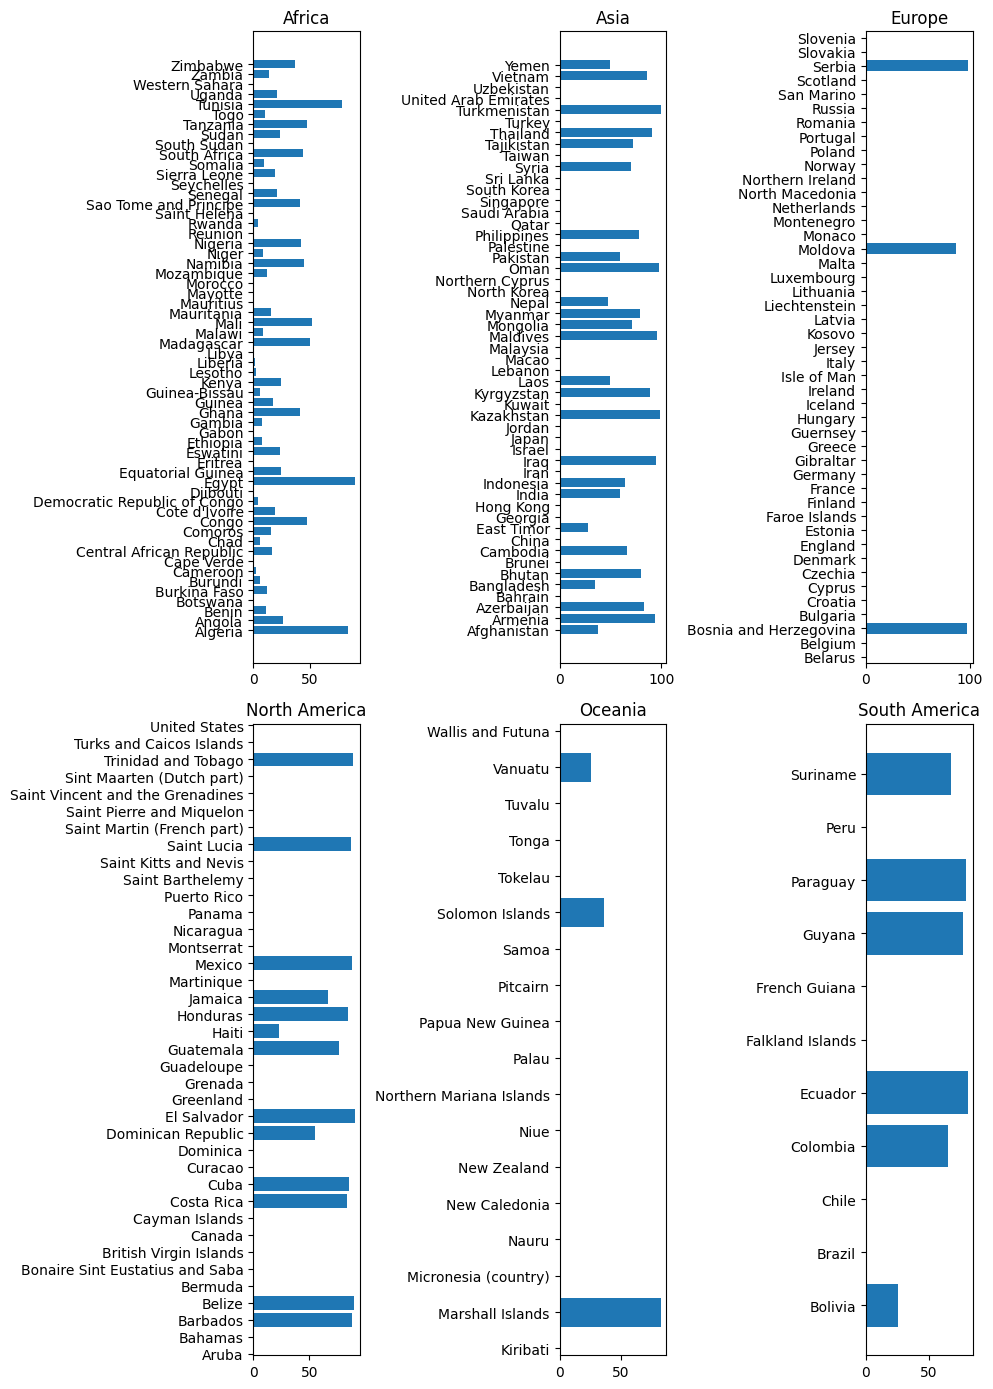

In [ ]:
# plotting bar graphs in the same figure to show the number of handwashing facilites for each location
fig, axes = plt.subplots(2,3)
axes[0,0].barh(location_africa, handwashing_africa)
axes[0,0].set_title('Africa')
axes[0,1].barh(location_asia, handwashing_asia)
axes[0,1].set_title('Asia')
axes[0,2].barh(location_europe, handwashing_europe)
axes[0,2].set_title('Europe')
axes[1,0].barh(location_namerica, handwashing_namerica)
axes[1,0].set_title('North America')
axes[1,1].barh(location_oceania, handwashing_oceania)
axes[1,1].set_title('Oceania')
axes[1,2].barh(location_samerica, handwashing_samerica)
axes[1,2].set_title('South America')
plt.tight_layout() # This makes it so the axes and words to do overlap

In [ ]:
# creating a new data set for the number of hospital beds.
df_hospital_beds = df.groupby(['continent', 'location'])['hospital_beds_per_thousand'].agg('mean').reset_index()
df_hospital_beds

,continent,location,hospital_beds_per_thousand
0,Africa,Algeria,1.9
1,Africa,Angola,NaN
2,Africa,Benin,0.5
3,Africa,Botswana,1.8
4,Africa,Burkina Faso,0.4
...,...,...,...
238,South America,Paraguay,1.3
239,South America,Peru,1.6
240,South America,Suriname,3.1
241,South America,Uruguay,2.8


In [ ]:
location_africa = []
beds_africa = []
location_asia = []
beds_asia =[]
location_europe = []
beds_europe = []
location_namerica = []
beds_namerica = []
location_samerica = []
beds_samerica = []
location_oceania = []
beds_oceania = []
for i, row in df_hospital_beds.iterrows():
  if row['continent'] == 'Africa' and row['location'] not in location_africa:
    location_africa.append(row['location'])
    beds_africa.append(row['hospital_beds_per_thousand'])
  if row['continent'] == 'Asia' and row['location'] not in location_asia:
    location_asia.append(row['location'])
    beds_asia.append(row['hospital_beds_per_thousand'])
  if row['continent'] == 'Europe' and row['location'] not in location_europe:
    location_europe.append(row['location'])
    beds_europe.append(row['hospital_beds_per_thousand'])
  if row['continent'] == 'North America' and row['location'] not in location_namerica:
    location_namerica.append(row['location'])
    beds_namerica.append(row['hospital_beds_per_thousand'])
  if row['continent'] == 'Oceania' and row['location'] not in location_oceania:
    location_oceania.append(row['location'])
    beds_oceania.append(row['hospital_beds_per_thousand'])
  if row['continent'] == 'South America' and row['location'] not in location_samerica:
    location_samerica.append(row['location'])
    beds_samerica.append(row['hospital_beds_per_thousand'])

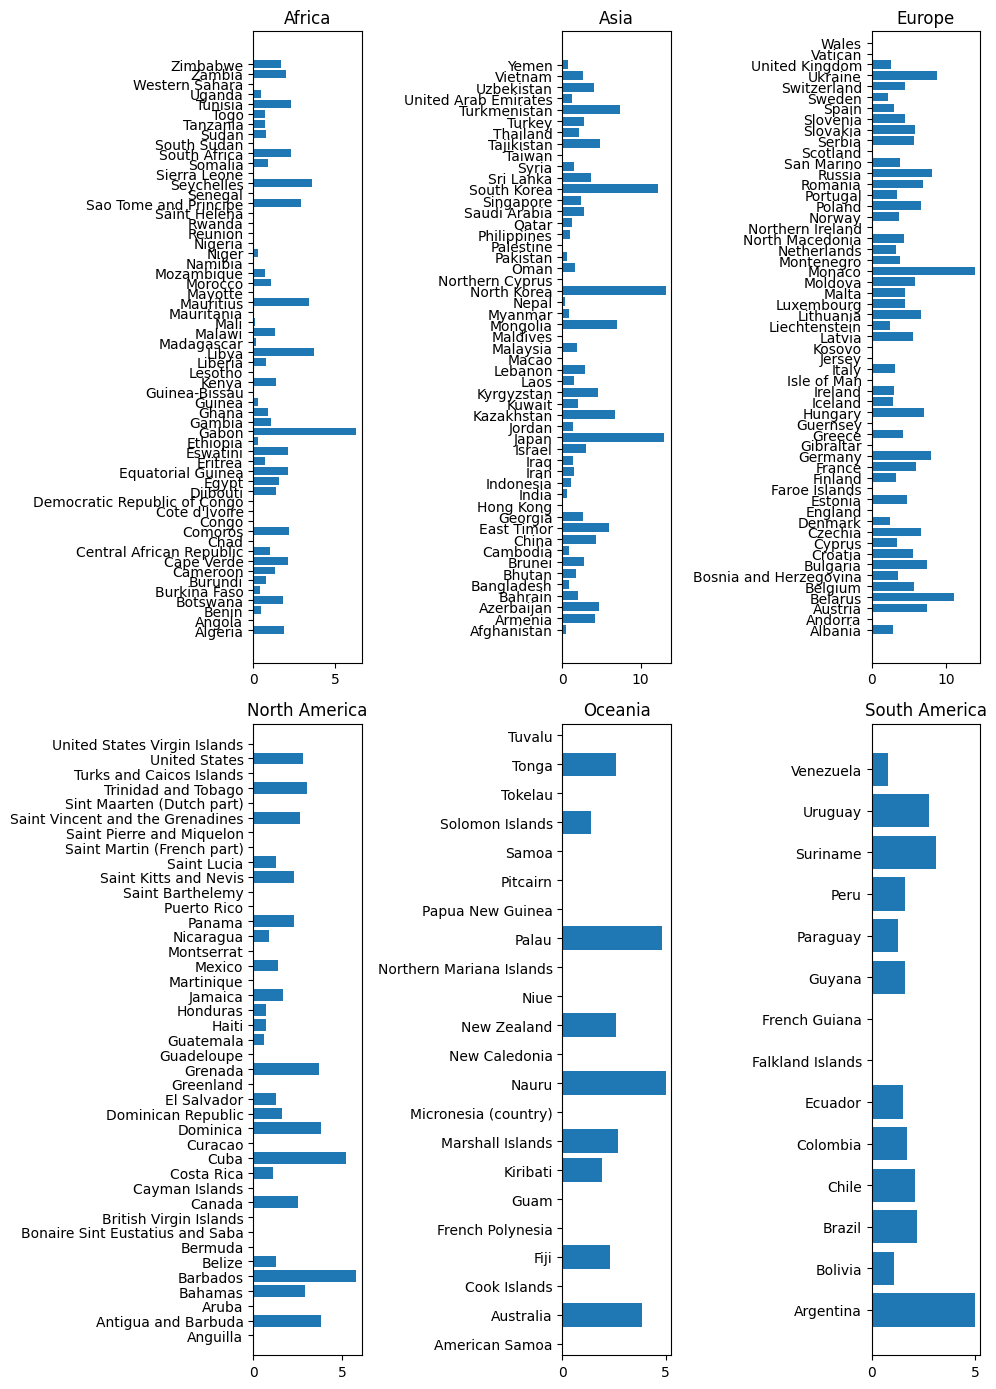

In [ ]:
fig, axes = plt.subplots(2,3)
axes[0,0].barh(location_africa, beds_africa)
axes[0,0].set_title('Africa')
axes[0,1].barh(location_asia, beds_asia)
axes[0,1].set_title('Asia')
axes[0,2].barh(location_europe, beds_europe)
axes[0,2].set_title('Europe')
axes[1,0].barh(location_namerica, beds_namerica)
axes[1,0].set_title('North America')
axes[1,1].barh(location_oceania, beds_oceania)
axes[1,1].set_title('Oceania')
axes[1,2].barh(location_samerica, beds_samerica)
axes[1,2].set_title('South America')
plt.tight_layout()

## How do handwashing facilities and hospital beds relate to the number of cases and deaths?


In [ ]:
# creating a data frame that only includes the tows with the total number of cases and deaths for each location
df_totals = df.groupby('location').tail(1)[['continent','location','total_cases', 'total_deaths', 'handwashing_facilities', 'hospital_beds_per_thousand']].reset_index().dropna()
# tail gives the last row for each location.
# the list after that gives every column I want in my data set
# dromna removes rows with missing data
df_totals

,index,continent,location,total_cases,total_deaths,handwashing_facilities,hospital_beds_per_thousand
0,1673,Asia,Afghanistan,235214.0,7998.0,37.746,0.5
3,6695,Africa,Algeria,272139.0,6881.0,83.741,1.9
10,18417,Asia,Armenia,452273.0,8777.0,94.043,4.2
15,26797,Asia,Azerbaijan,835757.0,10353.0,83.241,4.7
18,31819,Asia,Bangladesh,2051348.0,29499.0,34.808,0.8
...,...,...,...,...,...,...,...
235,398428,Africa,Uganda,172154.0,3632.0,21.222,0.5
247,419855,Asia,Vietnam,11624000.0,43206.0,85.847,2.6
252,426086,Asia,Yemen,11945.0,2159.0,49.542,0.7
253,427760,Africa,Zambia,349842.0,4077.0,13.938,2.0


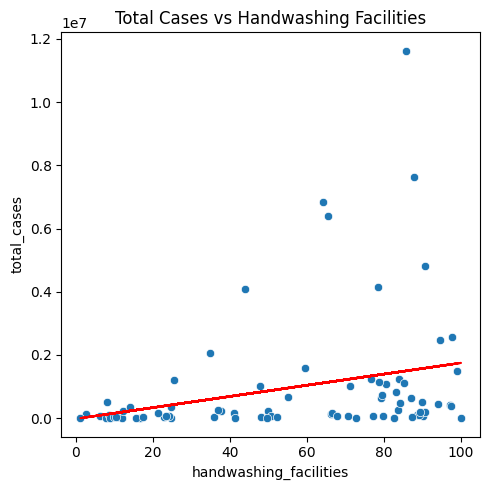

In [ ]:
# defining a fuction to fit the data
def model_function(x, m, b):
    return m*x + b

# performing the fit
initial_guess = [17674, 0]
params, covariance = curve_fit(model_function, df_totals['handwashing_facilities'], df_totals['total_cases'], p0=initial_guess)
m_fit, b_fit = params

# plotting both the data and the fit line
fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(data=df_totals, x='handwashing_facilities', y='total_cases')
plt.plot(df_totals['handwashing_facilities'], model_function(df_totals['handwashing_facilities'], *params), color='red', label='Fitted Curve')
ax.set_title("Total Cases vs Handwashing Facilities")
plt.tight_layout()

In [ ]:
# linear regression
slope, intercept, r_value, p_value, std_err = linregress(df_totals['handwashing_facilities'], df_totals['total_cases'])

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"R-squared: {r_value**2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Standard Error: {std_err:.4f}")

Slope: 17674.5420
Intercept: -18276.8038
R-squared: 0.0802
P-value: 0.0120
Standard Error: 6864.7023


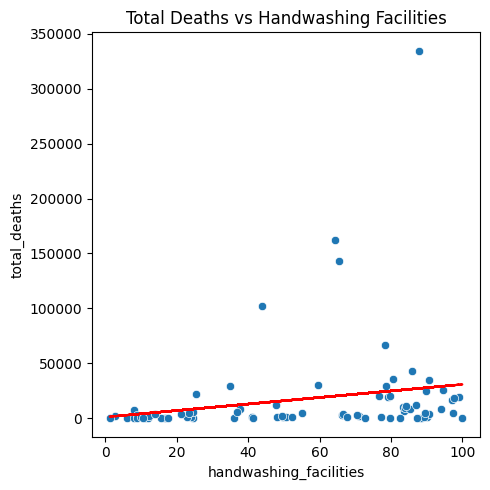

In [ ]:
initial_guess = [300, 0]
params, covariance = curve_fit(model_function, df_totals['handwashing_facilities'], df_totals['total_deaths'], p0=initial_guess)
m_fit, b_fit = params

fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(data=df_totals, x='handwashing_facilities', y='total_deaths')
plt.plot(df_totals['handwashing_facilities'], model_function(df_totals['handwashing_facilities'], *params), color='red', label='Fitted Curve')
ax.set_title("Total Deaths vs Handwashing Facilities")
plt.tight_layout()

In [ ]:
slope, intercept, r_value, p_value, std_err = linregress(df_totals['handwashing_facilities'], df_totals['total_deaths'])

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"R-squared: {r_value**2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Standard Error: {std_err:.4f}")

Slope: 297.1820
Intercept: 1043.6209
R-squared: 0.0423
P-value: 0.0709
Standard Error: 162.2284


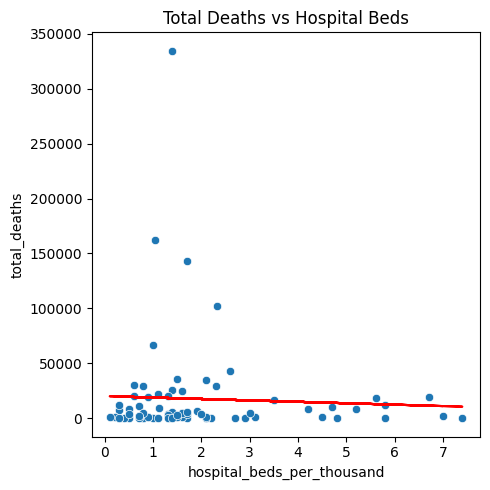

In [ ]:
initial_guess = [17000, 0]
params, covariance = curve_fit(model_function, df_totals['hospital_beds_per_thousand'], df_totals['total_'], p0=initial_guess)
m_fit, b_fit = params

fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(data=df_totals, x='hospital_beds_per_thousand', y='total_deaths')
plt.plot(df_totals['hospital_beds_per_thousand'], model_function(df_totals['hospital_beds_per_thousand'], *params), color='red', label='Fitted Curve')
ax.set_title("Total Deaths vs Hospital Beds")
plt.tight_layout()

In [ ]:
slope, intercept, r_value, p_value, std_err = linregress(df_totals['hospital_beds_per_thousand'], df_totals['total_deaths'])

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"R-squared: {r_value**2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Standard Error: {std_err:.4f}")

Slope: -1291.3705
Intercept: 20080.0601
R-squared: 0.0023
P-value: 0.6755
Standard Error: 3073.2290


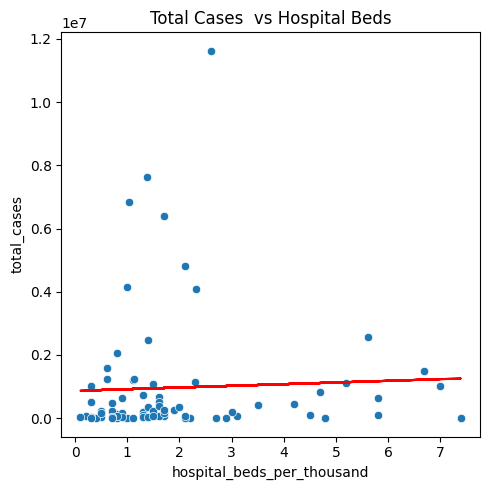

In [ ]:
initial_guess = [17000, 0]
params, covariance = curve_fit(model_function, df_totals['hospital_beds_per_thousand'], df_totals['total_cases'], p0=initial_guess)
m_fit, b_fit = params

fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(data=df_totals, x='hospital_beds_per_thousand', y='total_cases')
plt.plot(df_totals['hospital_beds_per_thousand'], model_function(df_totals['hospital_beds_per_thousand'], *params), color='red', label='Fitted Curve')
ax.set_title("Total Cases  vs Hospital Beds")
plt.tight_layout()

In [ ]:
slope, intercept, r_value, p_value, std_err = linregress(df_totals['hospital_beds_per_thousand'], df_totals['total_cases'])

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"R-squared: {r_value**2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Standard Error: {std_err:.4f}")

Slope: 52827.8867
Intercept: 865452.2313
R-squared: 0.0021
P-value: 0.6917
Standard Error: 132714.5389


## Conclusion

Based on the data provided in this notebook, the hypothesis was rejected. Directly looking at the number of handwashing facilities and hospital beds as they relate to total cases and deaths related to COVID-19 did not result in any statistically relevant relationship. Between locations, there was a large variance in the number of hospital facilities available. For this reason, I expected there to be enough data to provide a strong relationship. However, only one linear regression resulted in a significant p-value, and the relationship showed the opposite of what was expected. As the number of handwashing facilities increased, the number of total cases also increased. The hypothesis predicted that the number of total cases would decrease as handwashing facilities increased. Even the plot with a significant p-value had a low R-squared value and high error, indicating that the relationship is not very strong.

These results are likely due to the direct comparison of hospital facilities to total numbers. This neglects other factors like population and economics, which likely play a significant role. This study attempted to analyze the direct comparison, and by doing so, it can be concluded that a more in-depth analysis of contributing factors is necessary. Future research should look into the proportion of hospital facilities with the population in mind.
